# Experiment 22: ELoRA learning curve and parity

Five training-set sizes, validation-selected checkpoints, and matched validation/test evaluation.

Analysis date: 29 October 2026.

In [ ]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path('/Users/louismcauliffe/code/research/NequIP_experiments')
DATA = ROOT / 'experiments/21-23-LearningCurve-data'
FIG = ROOT / 'experiments/21-23-LearningCurve-figures'
metrics = pd.read_csv(DATA / 'metrics.csv')
manifest = json.loads((DATA / 'manifest.json').read_text())
assert metrics.export_matches_checkpoint.all()
valid = metrics.query("split == 'valid'")
np.testing.assert_allclose(valid.loss, valid.saved_valid_loss, rtol=1e-3, atol=1e-7)
for split in ('valid', 'test'):
    path = ROOT / f'data/nmr_iso/{split}.xyz'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest['input_sha256'][str(path)]
print('26 audited checkpoints: 25 primary models and one separate ELoRA pilot.')


In [ ]:
results = metrics.query('experiment == 22 and primary and split == "test"').sort_values(['n', 'experiment'])
display(results[['experiment', 'n', 'Si_rmse', 'O_rmse', 'loss', 'best_epoch', 'final_epoch', 'status', 'trainable_parameters']].reset_index(drop=True))

experiment,n,Si_rmse,O_rmse,loss,best_epoch,final_epoch,status,trainable_parameters
22,10,1.5861,4.0485,0.038517,267,567,Early stopping,29060
22,50,1.2805,2.8284,0.021466,158,458,Early stopping,29060
22,100,1.055,2.7446,0.017423,195,495,Early stopping,29060
22,200,0.87138,2.3796,0.012596,245,545,Early stopping,29060
22,800,0.67413,1.7195,0.0069523,301,577,Stopped before convergence,29060


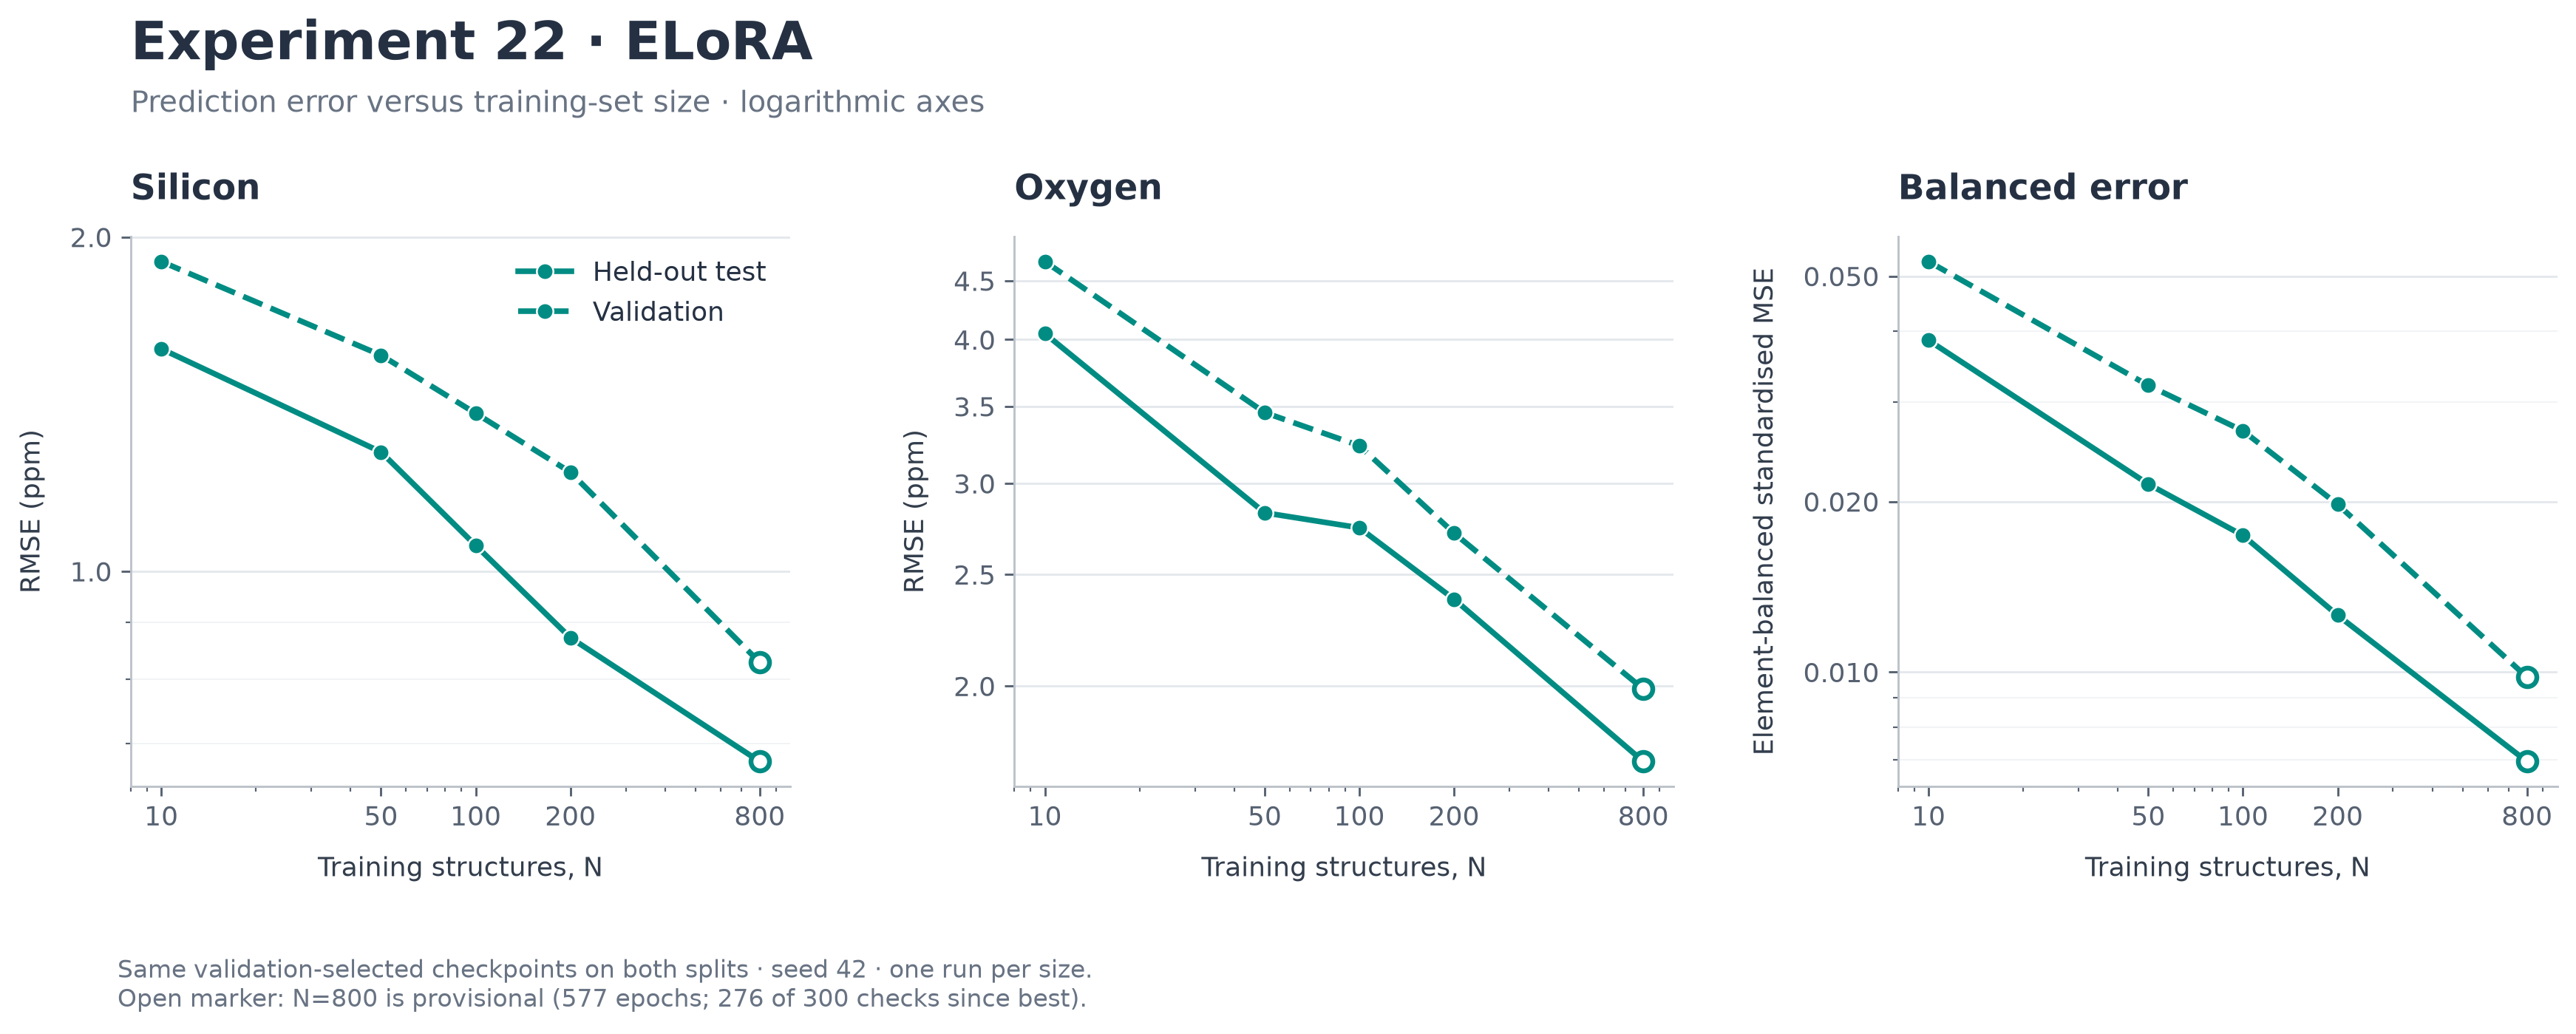

In [ ]:
display(Image(filename=str(FIG / '22-learning-curve-log-log.png')))

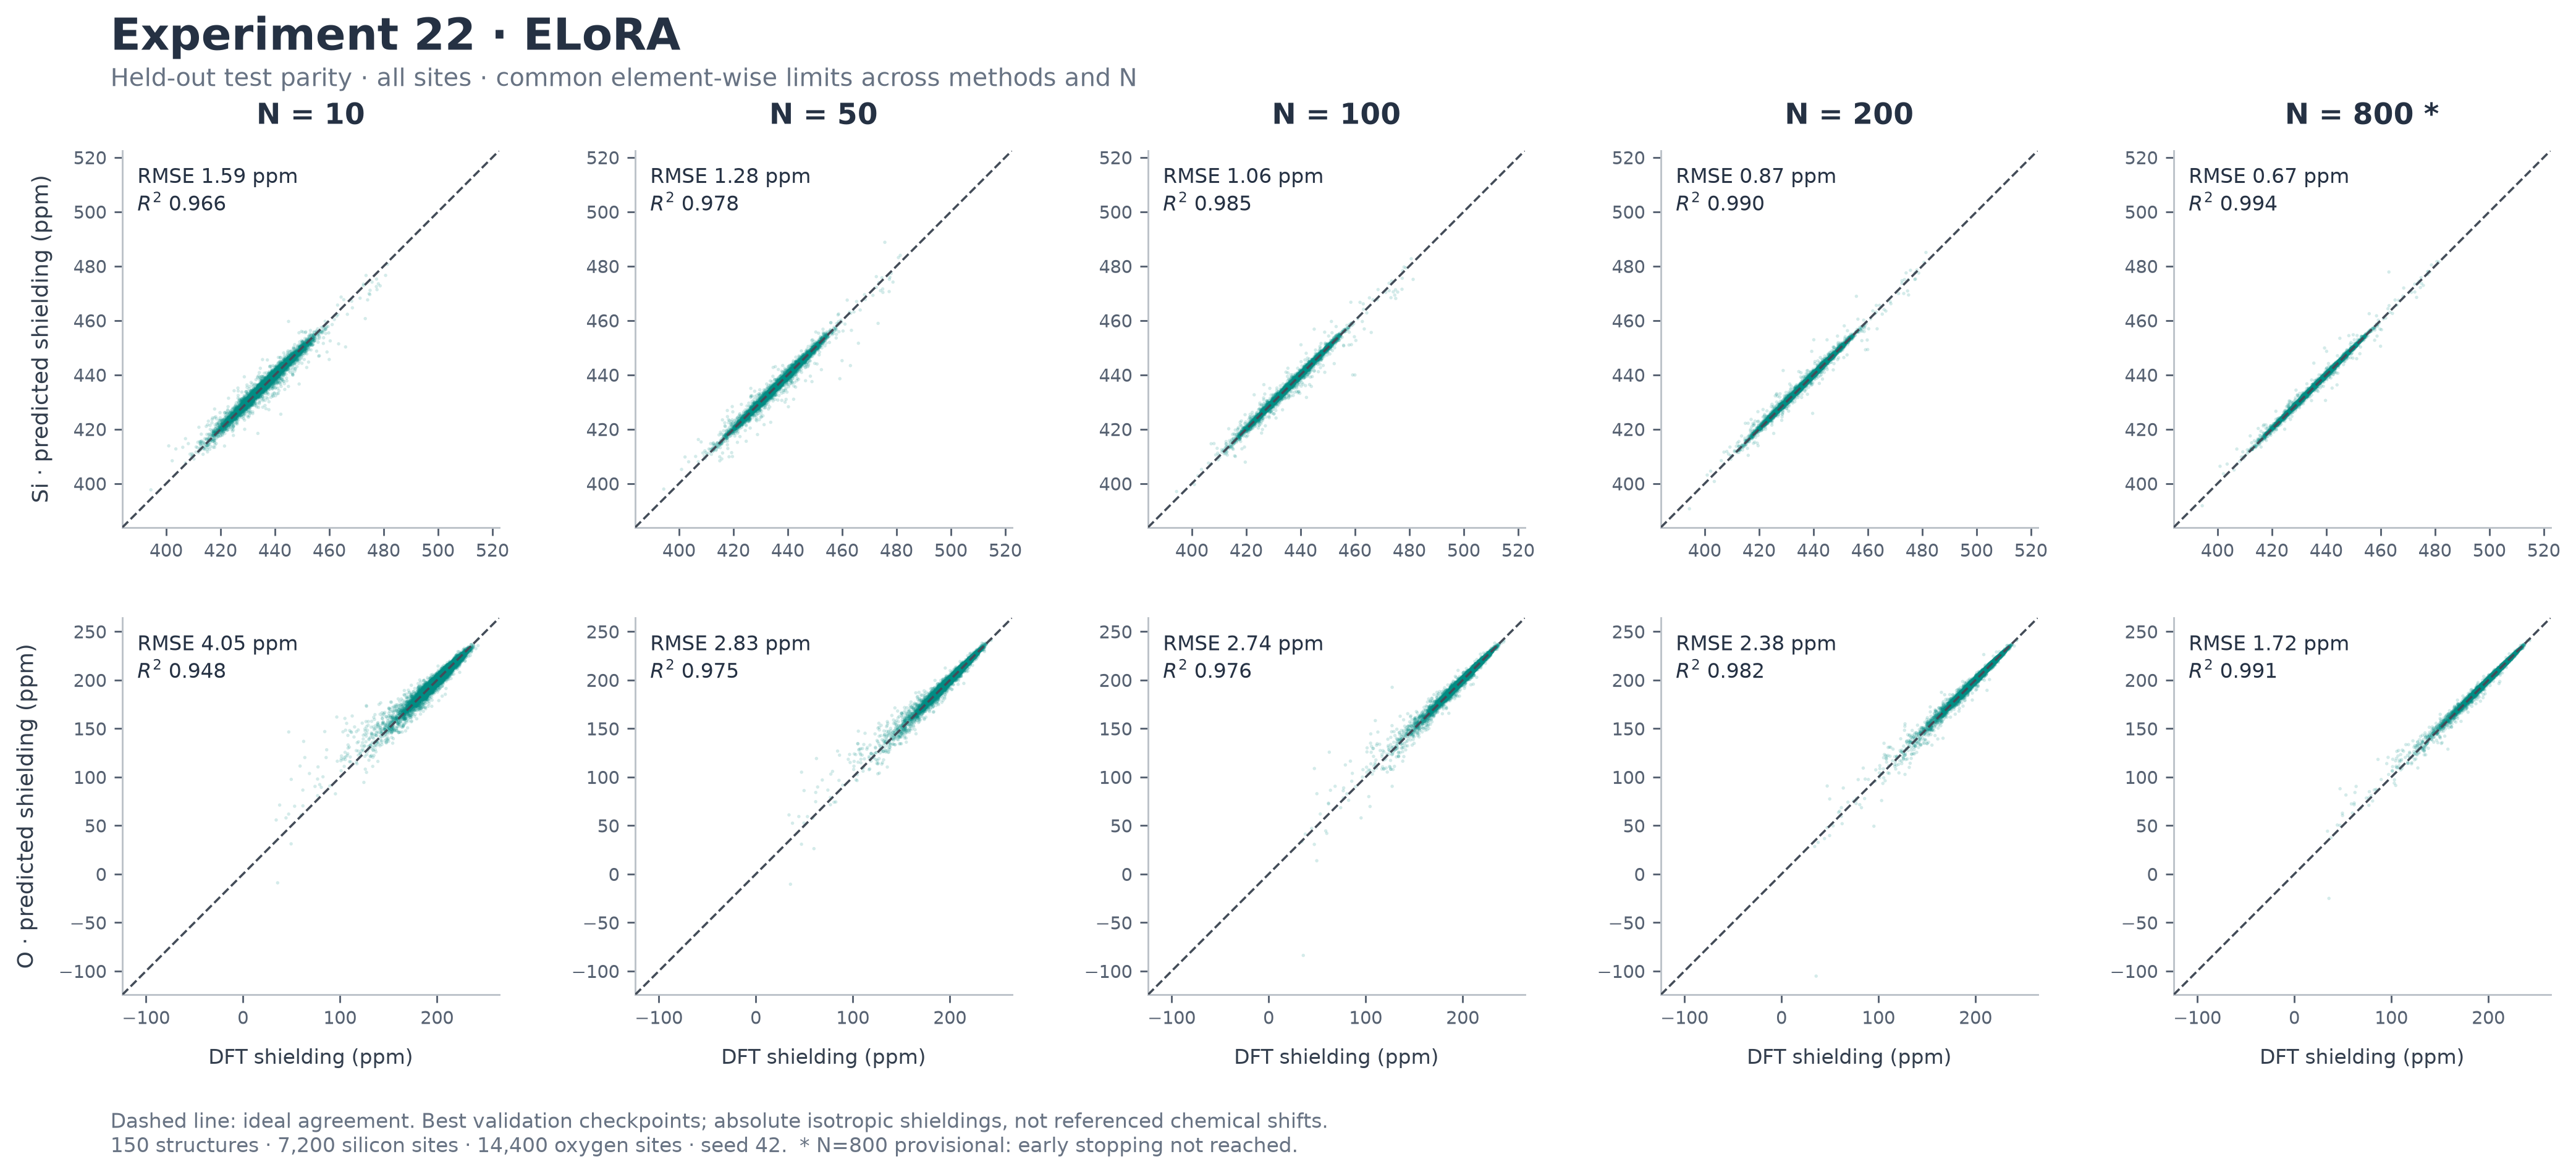

In [ ]:
display(Image(filename=str(FIG / '22-test-parity.png')))

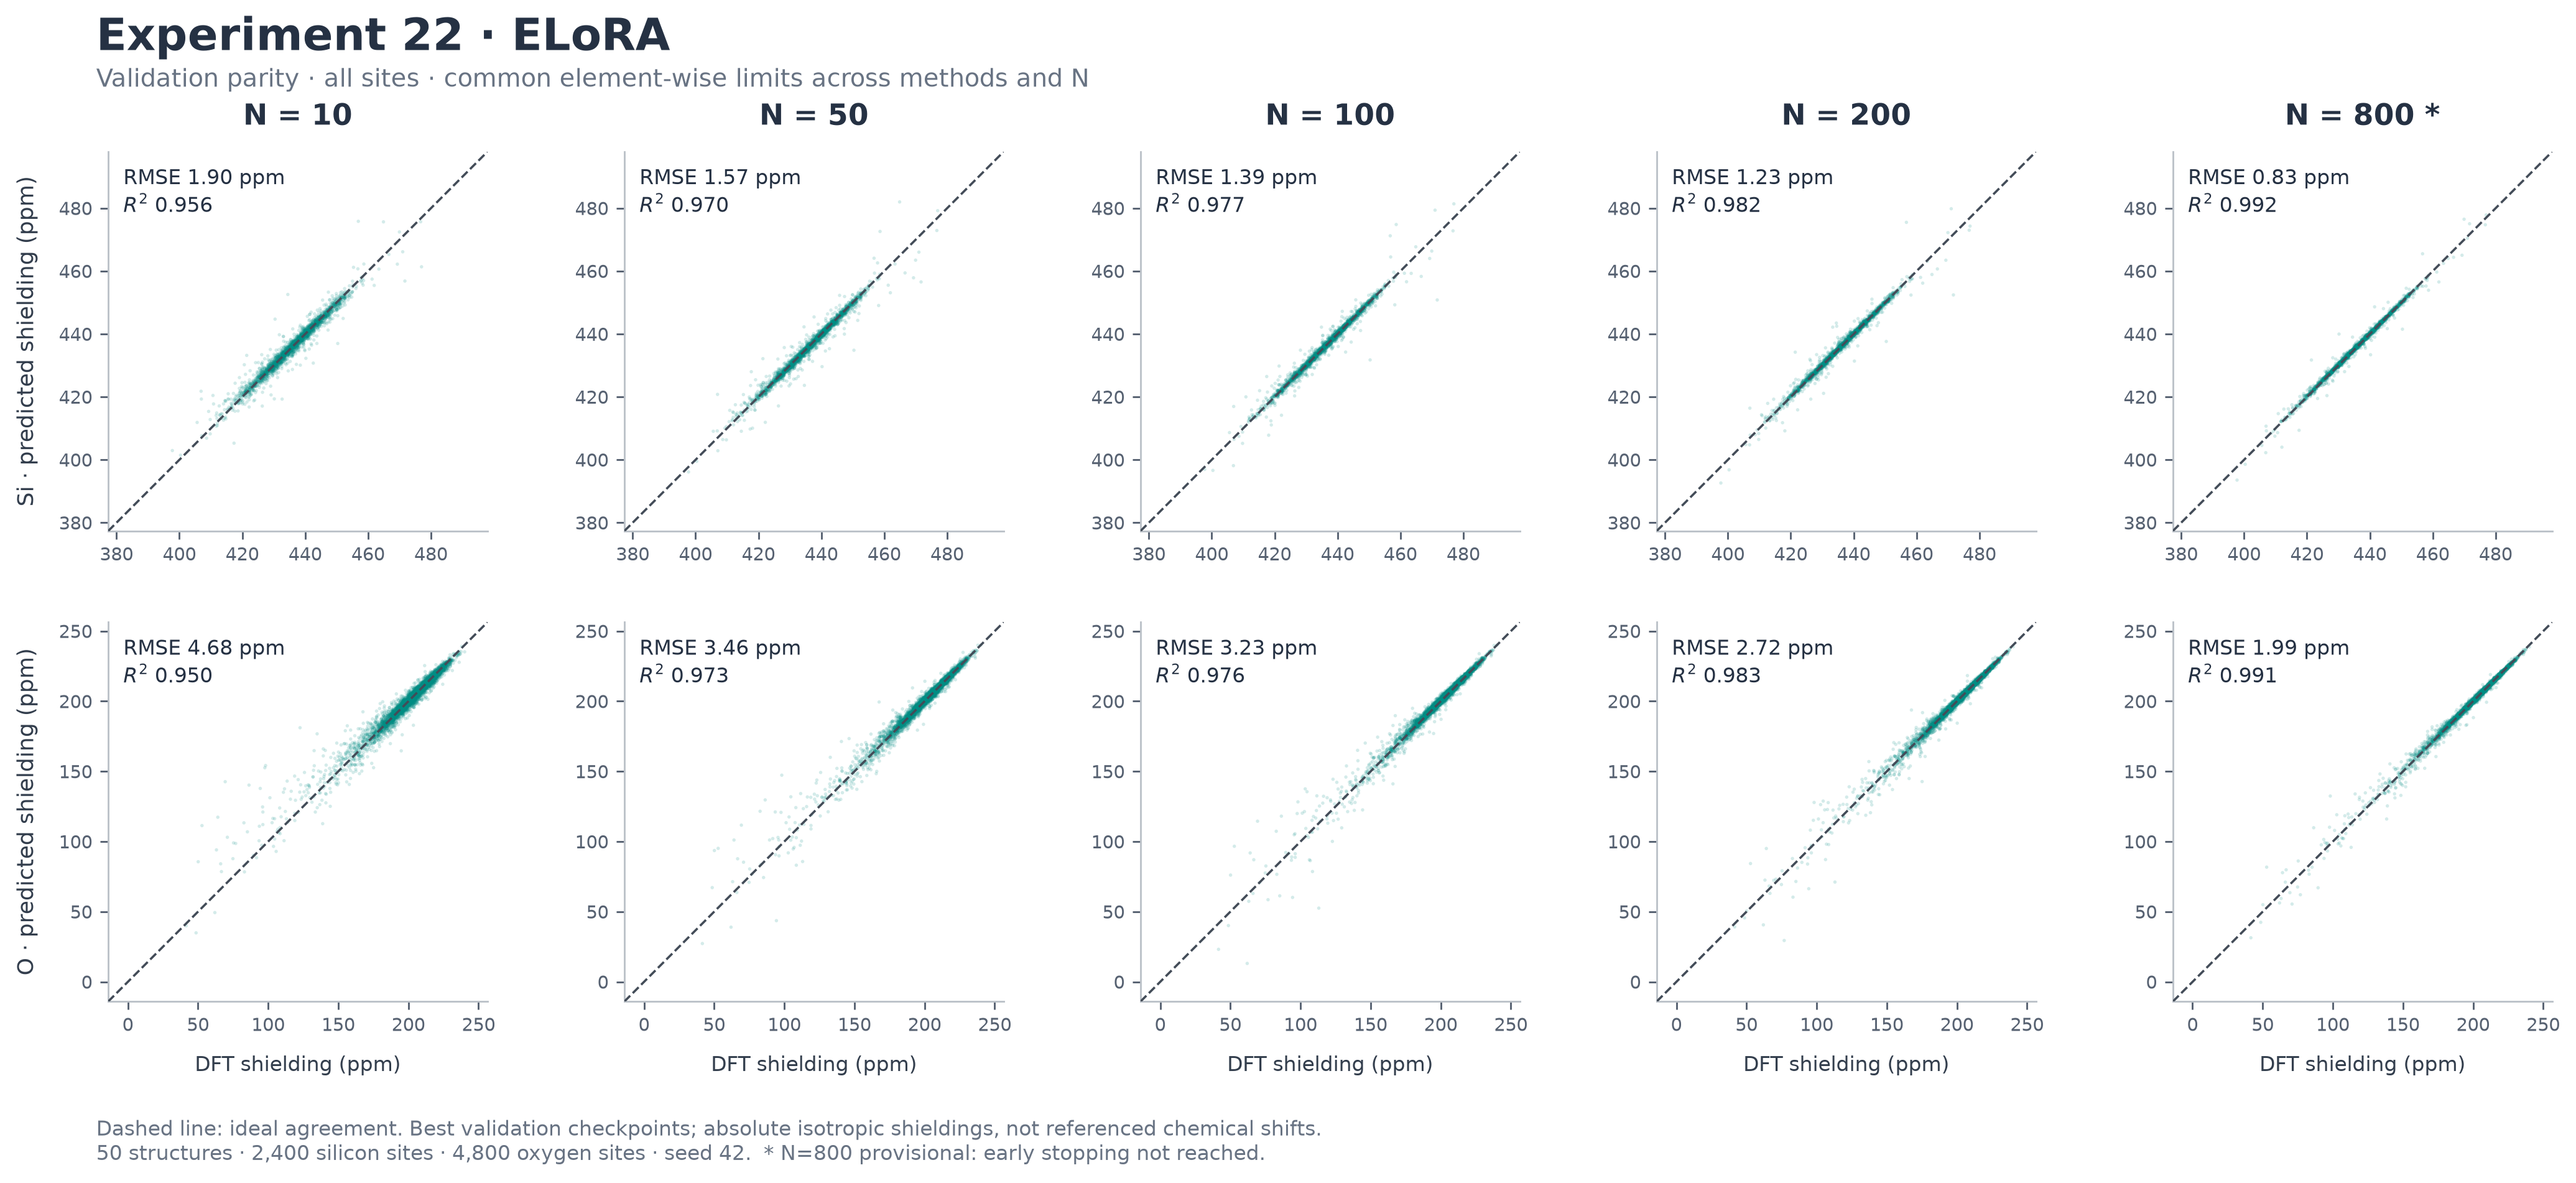

In [ ]:
display(Image(filename=str(FIG / '22-valid-parity.png')))

## N=100 pilot and sweep

The main curve uses **22-ELoRA-N100-R4-9201981**, submitted with the other four sizes. The earlier pilot **9201369** is retained and evaluated separately; no test-based selection or averaging is used.

In [ ]:
display(metrics.query('experiment == 22 and n == 100')[['run_id','primary','split','Si_rmse','O_rmse','loss']])